# IMPORT

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt


# FIX FOR THE KMEANS PROBLEM

In [2]:
# To solve the memory leak problem for K-Means in Windows
os.environ["OMP_NUM_THREADS"] = "6"

# DEFINE FOLDERS

In [3]:
BASE_FOLDER = Path("../data")
STATION_FEATURE_FOLDER = BASE_FOLDER / "02_features" / "station_features"
STATION_CLUSTER_FOLDER = BASE_FOLDER / "03_clustering" / "station_clusters"
CLUSTER_SUMMARY_FOLDER = BASE_FOLDER / "03_clustering" / "cluster_summary"
CLUSTER_PLOT_FOLDER = BASE_FOLDER / "03_clustering" / "cluster_plots"

folders = [STATION_FEATURE_FOLDER, STATION_CLUSTER_FOLDER, CLUSTER_SUMMARY_FOLDER, CLUSTER_PLOT_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [4]:
RANDOM_STATE = 42
K = 2 # Should be choosen after seeing the plot etc, but so far only 2 worked well so
ALL_FEATURES = True # If not true, we only use behavioral features(the most correlated 5 features) without the weather features

# LOAD DATA

In [5]:
df = pd.read_csv(f"{STATION_FEATURE_FOLDER}/station_features.csv")

print("Stations:", df.shape[0])

Stations: 1422


# ADD A NEW FEATURE

In [6]:
"""
stationcode,mean_usage,std_usage,min_usage,max_usage,mean_weekend,mean_weekday,day_usage,night_usage,daily_amplitude,
corr_weather_temperature_2m,corr_weather_wind_speed_10m,corr_weather_wind_direction_10m,corr_weather_weather_code,latitude,longitude,capacity
"""

"""
corr_weather_temperature_2m     *  +
corr_weather_wind_speed_10m     *  +
corr_weather_wind_direction_10m *  +
corr_weather_weather_code       * 
"""
# We did not continue on working on a new feature as the weather data does not correlate with stations that much.

'\ncorr_weather_temperature_2m     *  +\ncorr_weather_wind_speed_10m     *  +\ncorr_weather_wind_direction_10m *  +\ncorr_weather_weather_code       * \n'

# SELECT FEATURES FOR CLUSTERING

In [7]:
print(df.columns)

Index(['station_code', 'mean_usage', 'std_usage', 'min_usage', 'max_usage',
       'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage',
       'daily_amplitude', 'corr_temperature', 'corr_wind_speed',
       'corr_wind_direction', 'corr_weather_code', 'latitude', 'longitude',
       'capacity'],
      dtype='object')


In [8]:
"""
to exclude:
-stationcode
-latitude/longitude (for now)
-capacity (size != behavior)
"""
# # means we can remove to improve clustering quality
cluster_features = [
    "mean_usage",
    "mean_weekend",
    "mean_weekday",
    "std_usage", # put it back
    "daily_amplitude", # put it back
]
# We can remove them because the chosen 5 are the most correlated features.
# It is also visible in the methods below that this makes it easier to cluster.
# But for the sake of the hypothesis and project, we will keep them for now.
if ALL_FEATURES:
    cluster_features = cluster_features + [
        "day_usage", # put in all features
        "night_usage", # put in all features
        "corr_temperature", #
        "corr_wind_speed", #
        "corr_wind_direction", #
        "corr_weather_code", #
    ]

cluster_features = [c for c in cluster_features if c in df.columns]

X = df[cluster_features]
print("Clustering features:", cluster_features)

Clustering features: ['mean_usage', 'mean_weekend', 'mean_weekday', 'std_usage', 'daily_amplitude', 'day_usage', 'night_usage', 'corr_temperature', 'corr_wind_speed', 'corr_wind_direction', 'corr_weather_code']


# SCALE FEATURES

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# CHOOSE NUMBER OF CLUSTERS (ELBOW METHOD)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

2 9429.178189861646
3 8241.577553285762
4 7563.967460833986
5 6963.256758992066
6 6494.141539971514
7 6097.107433601265
8 5809.196089739012
9 5530.020955555611
10 5254.441679565509


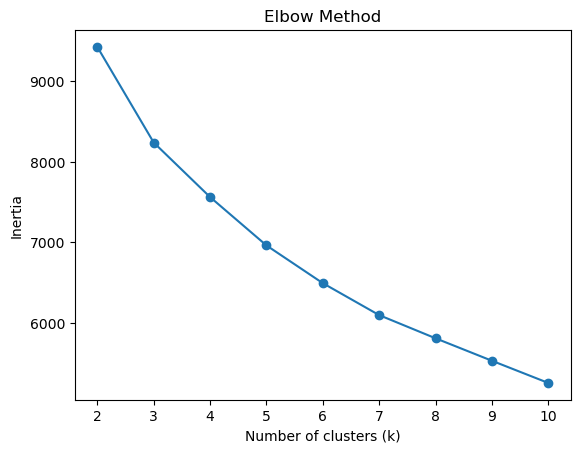

In [10]:
inertias = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

for x, y in zip(K_range, inertias):
    print(x, y)

plt.figure()
plt.plot(K_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# FOR ALL FEATURES
# Inertia drops quickly at small k, then flattens.
# No clear elbow, gains diminish after k=2–3.
# FOR BEHAVIORAL FEATURES
# Inertia decreases sharply from k=2 (2022) to k=3 (1270), then more slowly.
# No clear elbow, suggesting diminishing returns beyond k=2–3.

# CHOOSE NUMBER OF CLUSTERS (SILHOUETTE SCORE)

In [11]:
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} -> silhouette = {score:.3f}")

# FOR ALL FEATURES
# Highest score at k=2 (~0.34), indicating moderate cluster separation.
# Scores drop or remain similar for higher k, showing weaker distinction.
# FOR BEHAVIORAL FEATURES
# k=2 -> 0.589 (highest, best-separated clusters)
# k=3 -> 0.484, k=4 -> 0.391, k=5 -> 0.410, k=6 -> 0.352, k=7 -> 0.340
# Adding more clusters reduces separation.

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=2 -> silhouette = 0.348


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=3 -> silhouette = 0.273


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=4 -> silhouette = 0.219


... (2 outputs left out)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=6 -> silhouette = 0.182


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=7 -> silhouette = 0.173


# FINAL CLUSTERING

In [12]:
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50)
df["cluster"] = kmeans.fit_predict(X_scaled)

display(df["cluster"].value_counts())


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


cluster
0    743
1    679
Name: count, dtype: int64

# GET FILE TAG

In [13]:
CLUSTER_METHOD = "kmeans"
FEATURE_SET_NAME = "behavior+weather" if ALL_FEATURES else "behavior"
FILE_TAG = f"{CLUSTER_METHOD}_k{K}_feat_{FEATURE_SET_NAME}_rs{RANDOM_STATE}"
# We do this to not have complicated file names and to have a fixed name system

# SAVE STATION-CLUSTER MAPPING

In [14]:
df[["station_code", "cluster"]].to_csv(
    f"{STATION_CLUSTER_FOLDER}/station_clusters_{FILE_TAG}.csv", index=False
)

print(f"Saved {STATION_CLUSTER_FOLDER}/station_clusters_{FILE_TAG}.csv")

Saved ..\data\03_clustering\station_clusters/station_clusters_kmeans_k2_feat_behavior+weather_rs42.csv


# UNDERSTANDING WHAT EACH CLUSTER MEANS

In [15]:
cluster_summary = (
    df.groupby("cluster")[cluster_features]
    .mean()
    .round(3)
)

cluster_summary.to_csv(f"{CLUSTER_SUMMARY_FOLDER}/cluster_summary_{FILE_TAG}.csv")
display(cluster_summary)
print(f"Saved: {CLUSTER_SUMMARY_FOLDER}/cluster_summary_{FILE_TAG}.csv")

,mean_usage,mean_weekend,mean_weekday,std_usage,daily_amplitude,day_usage,night_usage,corr_temperature,corr_wind_speed,corr_wind_direction,corr_weather_code
cluster,,,,,,,,,,,
0,0.253,0.261,0.251,0.185,0.200,0.228,0.268,-0.109,-0.051,-0.059,0.005
1,0.551,0.553,0.550,0.245,0.269,0.562,0.545,-0.007,0.032,0.023,0.011


Saved: ..\data\03_clustering\cluster_summary/cluster_summary_kmeans_k2_feat_behavior+weather_rs42.csv


# VISUAL CHECK

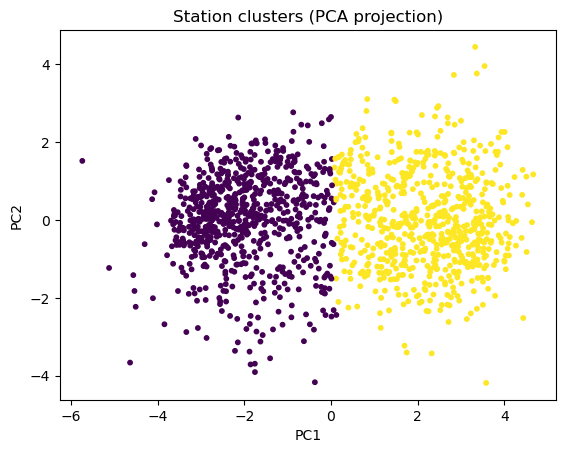

In [16]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], s=10)
plt.title("Station clusters (PCA projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.savefig(f"{CLUSTER_PLOT_FOLDER}/station_clusters_pca_{FILE_TAG}.png", dpi=300, bbox_inches='tight')
plt.show()


kmeans.cluster_centers_: [[-0.82781798 -0.77175977 -0.83248903 -0.63007162 -0.28075193 -0.79304243
  -0.77103809 -0.32138583 -0.34107022 -0.313411   -0.04155794]
 [ 0.90584501  0.84450296  0.91095633  0.68945981  0.30721456  0.86779164
   0.84371326  0.35167846  0.37321822  0.34295195  0.04547504]]


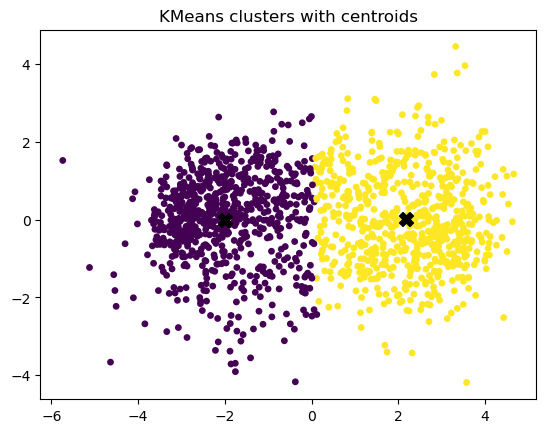

In [17]:
centroids = pca.transform(kmeans.cluster_centers_)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], s=15)
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    c="black", s=100, marker="X"
)
plt.title("KMeans clusters with centroids")

print(f"kmeans.cluster_centers_: {kmeans.cluster_centers_}")


In [18]:
centroids_pca = pca.transform(kmeans.cluster_centers_)

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)



In [19]:
grid_points = np.c_[xx.ravel(), yy.ravel()]

distances = np.linalg.norm(
    grid_points[:, None, :] - centroids_pca[None, :, :],
    axis=2
)

Z = np.argmin(distances, axis=1)
Z = Z.reshape(xx.shape)


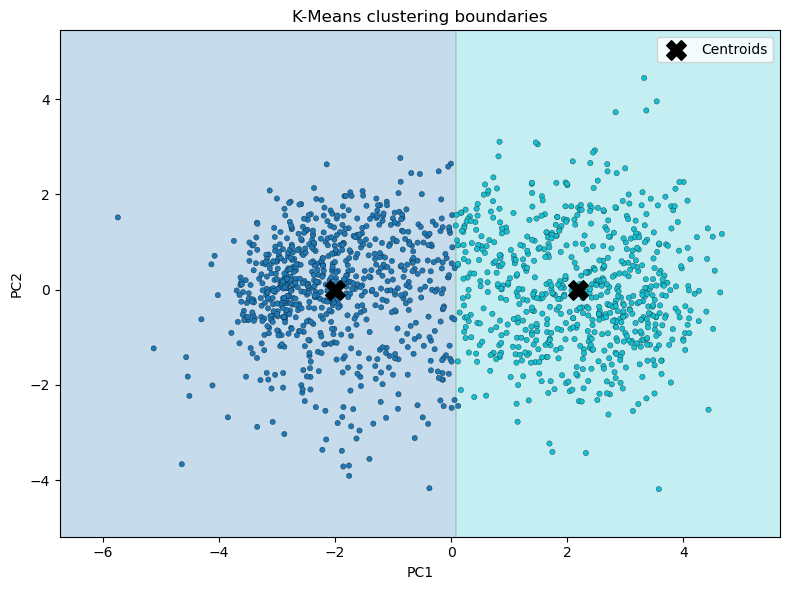

[[-1.99732091e+00 -8.90066522e-04]
 [ 2.18558091e+00  9.73960863e-04]]


In [20]:
plt.figure(figsize=(8, 6))

# Decision regions
plt.contourf(
    xx, yy, Z,
    alpha=0.25,
    cmap="tab10"
)

# Data points
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    s=15,
    cmap="tab10",
    edgecolor="k",
    linewidth=0.2
)

# Centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    s=200,
    marker="X",
    label="Centroids"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means clustering boundaries")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{CLUSTER_PLOT_FOLDER}/kmeans_boundaries_pca_{FILE_TAG}.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print(centroids_pca)